# Local Preprocessing
## Key Concepts
- **Local preprocessing** refers to image operations that modify pixel values based on their neighborhood, enhancing features like edges, textures, or contrast.
- **Convolution** is a fundamental operation that applies a filter (kernel) to an image to detect patterns or smooth variations.
- **Filtering** is used for tasks such as noise reduction, sharpening, or edge detection.

## Convolution  
- **Definition:** A mathematical operation where a kernel (small matrix) slides over the image, computing weighted sums of pixel neighborhoods.  
- **Common Filters:**  
  - **Smoothing (Blurring):** Reduces noise using kernels like Gaussian or averaging.  
  - **Sharpening:** Enhances details by emphasizing differences between neighboring pixels.  
  - **Edge Detection:** Identifies boundaries in an image using Sobel, Prewitt, or Laplacian filters.  

- **Example of 1D convolution:**  
![1D Conv](https://upload.wikimedia.org/wikipedia/commons/b/b9/Convolution_of_spiky_function_with_box2.gif)
- **Example of 2D convolution:**  
![2D Conv](https://iq.opengenus.org/content/images/2023/01/2023_01_20_0tc_Kleki-min.png)

### Mathematical Representation  
$$ I'(x, y) = \sum\limits_{i} \sum\limits_{j} K(i, j) \cdot I(x - i, y - j) $$

where $ K $ is the kernel and $ I $ is the input image.  

In [10]:
from math import sqrt

import numpy as np
import scipy.signal

# Define input signal and kernel
input_signal = np.array([3, 10, 10, 1, 2, 2])
kernel = np.array([1, 2, -1])

# Perform 1D convolution
output_signal = np.convolve(input_signal, kernel)

# Print numerical values
print(f"Input Signal: {input_signal.tolist()}")
print(f"Kernel: {kernel.tolist()}")
print(f"Output Signal: {output_signal.tolist()}")


Input Signal: [3, 10, 10, 1, 2, 2]
Kernel: [1, 2, -1]
Output Signal: [3, 16, 27, 11, -6, 5, 2, -2]


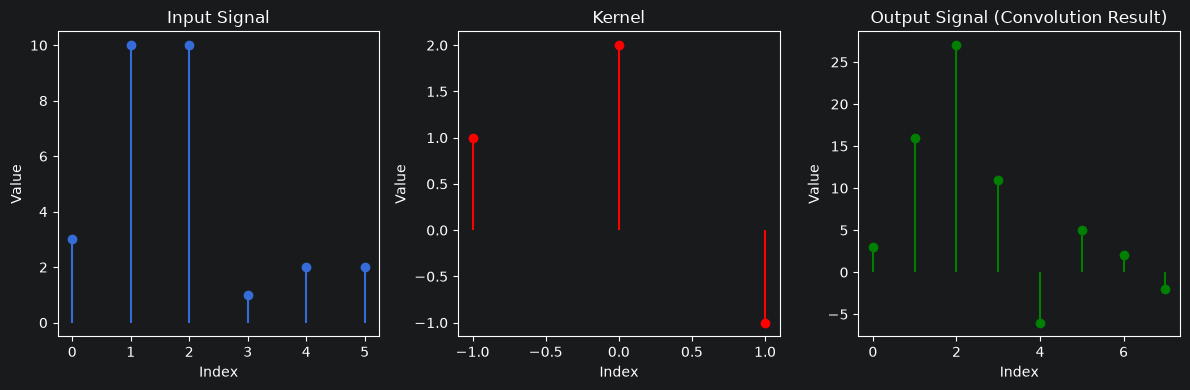

In [11]:
import matplotlib.pyplot as plt

# Create x-axis indices for plotting
input_x = np.arange(len(input_signal))
kernel_x = np.arange(len(kernel)) - len(kernel) // 2  # center kernel around zero (// -> divide and then floor)
output_x = np.arange(len(output_signal))

# Plot input signal
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.stem(input_x, input_signal, basefmt=' ')
plt.title('Input Signal')
plt.xlabel('Index')
plt.ylabel('Value')

# Plot kernel
plt.subplot(1, 3, 2)
plt.stem(kernel_x, kernel, basefmt=' ', linefmt='r', markerfmt='ro')
plt.title('Kernel')
plt.xlabel('Index')
plt.ylabel('Value')

# Plot output signal
plt.subplot(1, 3, 3)
plt.stem(output_x, output_signal, basefmt=' ', linefmt='g', markerfmt='go')
plt.title('Output Signal (Convolution Result)')
plt.xlabel('Index')
plt.ylabel('Value')

# Adjust layout and show
plt.tight_layout()
plt.show()

And now, let's move to 2D convolution...

**Note:**  
We will use `scipy` library for 2D convolution as it efficiently handles boundary conditions and demonstrates key filtering concepts.

## Image Smoothing
Image Smoothing is used to reduce noise in an image by averaging or filtering pixel values within a neighborhood.

### 1. Mean Filter (linear)
Replaces each pixel with the average of its neighbors. Different mask types affect the smoothing result:
- **Even Mask** (Standard mean filter):
  $$ K = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix} $$

- **Center Point Advantage** (Higher weight at center, preserves details better):
  $$ K = \frac{1}{16} \begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix} $$

- **Center Point Disadvantage** (Lower weight at center, stronger smoothing):
  $$ K = \frac{1}{12} \begin{bmatrix} 2 & 1 & 2 \\ 1 & 0 & 1 \\ 2 & 1 & 2 \end{bmatrix} $$

### 2. Gaussian Filter (linear)
Preserves edges better than a simple mean filter. The kernel is defined by a **Gaussian function**:
$$ G(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}} $$
where $ \sigma $ controls the level of smoothing.

### 3. Median Filter (nonlinear)
Replaces each pixel with the median value. Particularly effective for removing **salt-and-pepper noise**, i.e., random black and white dots.

### 4. Max/Min Filter (nonlinear)
Replaces each pixel with the minimum/maximum value.

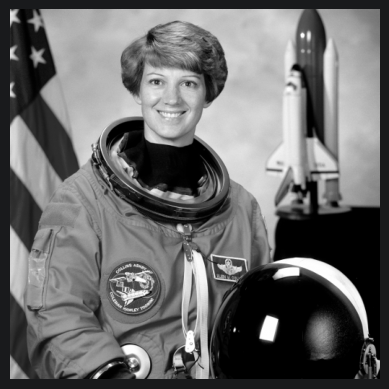

In [9]:
from skimage import data
from PIL import Image

# Load image and convert to grayscale (and then to numpy array)
img_gray = Image.fromarray(data.astronaut()).convert('L')
img_gray = np.array(img_gray)

# Display the image
plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.show()

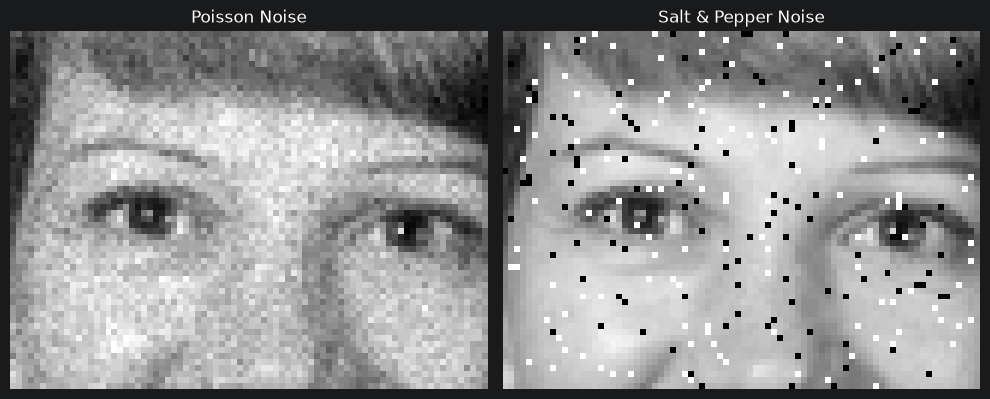

In [7]:
from skimage.util import random_noise

# Crop the image
cropped = np.array(img_gray)[70:130, 180:260]

# Add some noise
# 1. poisson
cropped_psn = random_noise(cropped, mode='poisson')
cropped_psn = (cropped_psn * 255).astype(np.uint8)
# 2. salt-and-pepper
cropped_sap = random_noise(cropped, mode='s&p', amount=0.05)
cropped_sap = (cropped_sap * 255).astype(np.uint8)

# Display noisy images
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(cropped_psn, cmap='gray')
axes[0].set_title('Poisson Noise')
axes[0].axis('off')

axes[1].imshow(cropped_sap, cmap='gray')
axes[1].set_title('Salt & Pepper Noise')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Apply a simple averaging filter using convolution (individual work)
Apply a **3×3 averaging filter** to an image to understand how convolution works. This filter smooths the image by reducing sharp variations, commonly used for **noise reduction**.

**Instructions:**
1. Define a 3×3 averaging kernel, e.g.:
   $$ K = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix} $$
2. Apply 2D convolution to the noisy images using `scipy.signal.convolve2d`.
3. Store the results into the `filtered_psn` and `filtered_sap` variables.
4. Visualize the original and filtered image side by side (include annotations, i.e., title).

**Hints:**
- Use `mode="same"` in `convolve2d` to keep the output size the same as the input.
- Using `boundary='wrap'` makes the image edges wrap around, avoiding border effects.
- Convert the image to `float` before convolution to avoid data type issues.

**Note:**
Dividing the kernel by the sum of its elements ensures that the overall brightness of the image remains unchanged, preventing unintended darkening or brightening effects.

#### Code (scroll down)

(np.float64(-0.5), np.float64(79.5), np.float64(59.5), np.float64(-0.5))

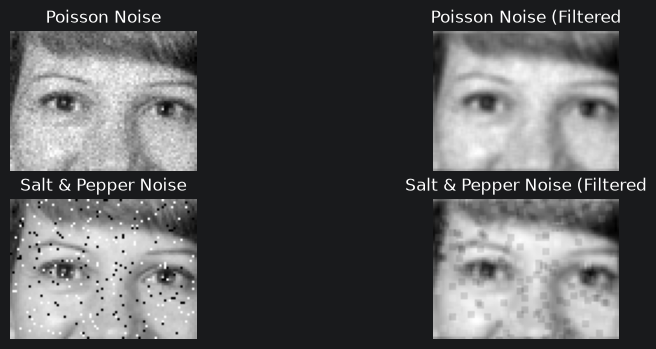

In [16]:
from scipy.signal import convolve2d

# The complete code will be provided during the exercise
# 1. Define the kernel
avg_kernel = np.full((3,3), 1).astype(np.float16) # Create averaging kernel
avg_kernel *= avg_kernel.size  # Divide by the number of its element

cropped_psn = cropped_psn.astype(float) # Convert to float as instructed
filtered_psn = scipy.signal.convolve2d(cropped_psn, avg_kernel, mode='same', boundary='wrap') # Convolute

cropped_sap = cropped_sap.astype(float) # Convertto float  as instructed
filtered_sap = scipy.signal.convolve2d(cropped_sap, avg_kernel, mode='same', boundary='wrap') # Convolute

# Display noisy images (Plot copied from previous code cell)
fig, axes = plt.subplots(2, 2, figsize=(10, 4))

axes[0, 0].imshow(cropped_psn, cmap='gray')
axes[0, 0].set_title('Poisson Noise')
axes[0, 0].axis('off')

axes[0, 1].imshow(filtered_psn, cmap='gray')
axes[0, 1].set_title('Poisson Noise (Filtered')
axes[0, 1].axis('off')

axes[1, 0].imshow(cropped_sap, cmap='gray')
axes[1, 0].set_title('Salt & Pepper Noise')
axes[1, 0].axis('off')

axes[1, 1].imshow(filtered_sap, cmap='gray')
axes[1, 1].set_title('Salt & Pepper Noise (Filtered')
axes[1, 1].axis('off')


### Comparison with other techniques

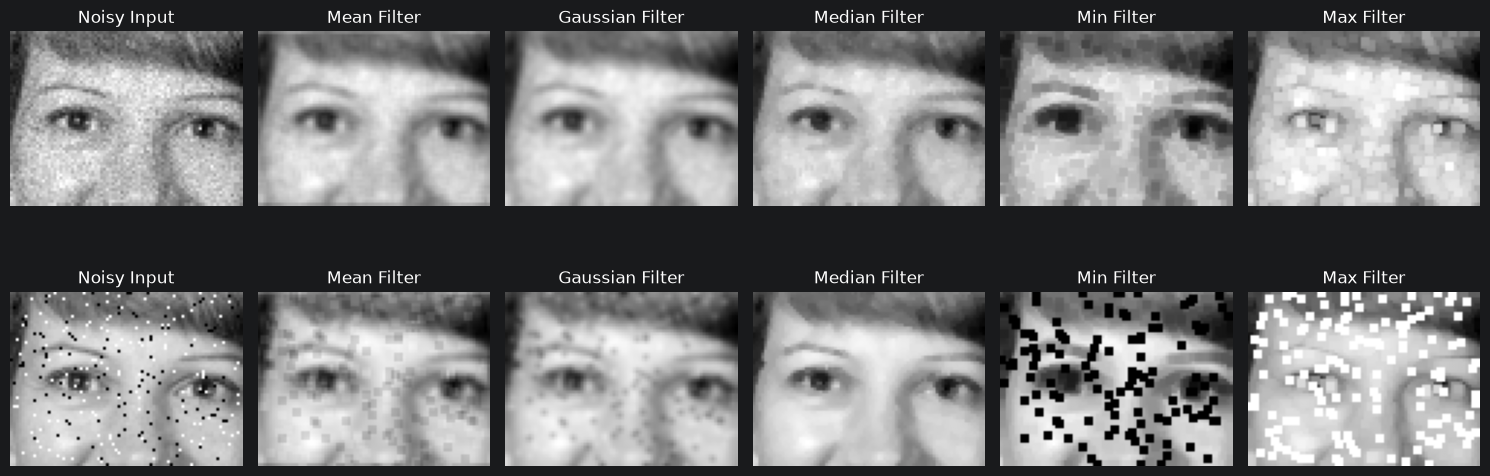

In [17]:
from scipy.ndimage import gaussian_filter, median_filter, minimum_filter, maximum_filter

# Prepare inputs and corresponding already filtered images
inputs = [cropped_psn, cropped_sap]
avg_filtered = [filtered_psn, filtered_sap]

_, axes = plt.subplots(2, 6, figsize=(15, 6))
for i in range(2):
    # Apply filters
    gaussian_filtered = gaussian_filter(inputs[i], sigma=1)
    median_filtered = median_filter(inputs[i], size=3)
    min_filtered = minimum_filter(inputs[i], size=3)
    max_filtered = maximum_filter(inputs[i], size=3)
    
    # Plot original and filtered images
    axes[i, 0].imshow(inputs[i], cmap='gray')
    axes[i, 0].set_title('Noisy Input')
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(avg_filtered[i], cmap='gray')
    axes[i, 1].set_title('Mean Filter')
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(gaussian_filtered, cmap='gray')
    axes[i, 2].set_title('Gaussian Filter')
    axes[i, 2].axis('off')
    
    axes[i, 3].imshow(median_filtered, cmap='gray')
    axes[i, 3].set_title('Median Filter')
    axes[i, 3].axis('off')
    
    axes[i, 4].imshow(min_filtered, cmap='gray')
    axes[i, 4].set_title('Min Filter')
    axes[i, 4].axis('off')
    
    axes[i, 5].imshow(max_filtered, cmap='gray')
    axes[i, 5].set_title('Max Filter')
    axes[i, 5].axis('off')

plt.tight_layout()
plt.show()

### Convolution behind borders
1. Fill (Constant Padding)
    - Out-of-bounds pixels are replaced with a constant value (often 0).
    - Results in dark borders or artifacts.
    - Example: `boundary="fill", fillvalue=0`
2. Wrap (Periodic Extension)
    - The image is wrapped around, so the leftmost pixels act as neighbors to the rightmost ones.
    - Useful for seamless textures, but can create unrealistic edges in normal images.
    - Example: `boundary="wrap"`
3. Symmetric (Mirror Padding)
    - The image is mirrored along the edges, creating a smooth transition.
    - Example: `boundary="symm"`

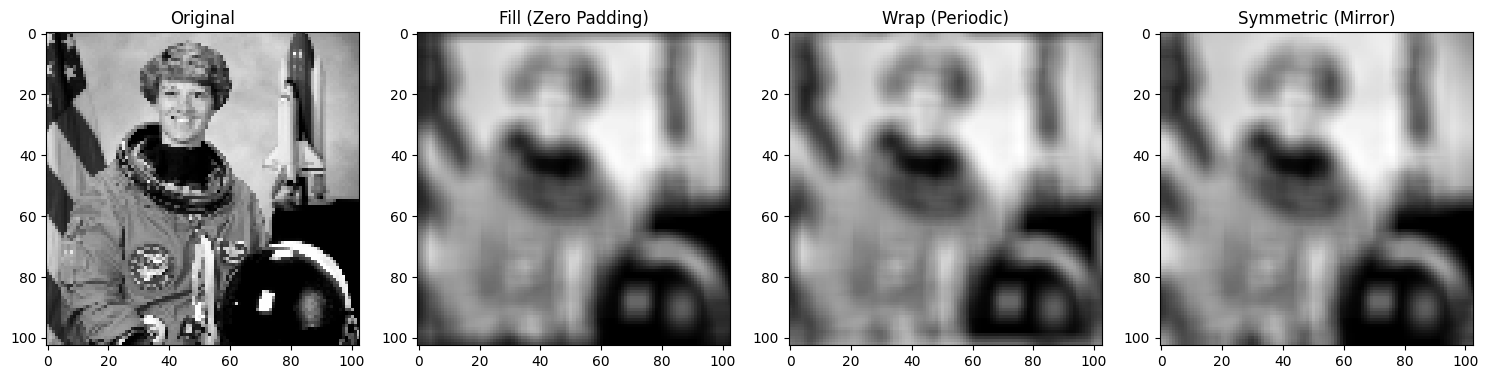

In [7]:
# Apply convolution with different boundary modes
kernel_9x9 = np.ones((9, 9))
kernel_9x9 /= np.sum(kernel)  # eq. to: kernel_9x9 = kernel_9x9 / np.sum(kernel)
img_resized = img_gray[::5, ::5]
modes = {
    'Fill (Zero Padding)': convolve2d(img_resized, kernel_9x9, mode='same', boundary='fill', fillvalue=0),
    'Wrap (Periodic)': convolve2d(img_resized, kernel_9x9, mode='same', boundary='wrap'),
    'Symmetric (Mirror)': convolve2d(img_resized, kernel_9x9, mode='same', boundary='symm'),
}

# Plot results
_, axes = plt.subplots(1, 4, figsize=(15, 5))
axes[0].imshow(img_resized, cmap='gray')
axes[0].set_title('Original')

for ax, (title, result) in zip(axes[1:], modes.items()):
    ax.imshow(result, cmap='gray')
    ax.set_title(title)

plt.tight_layout()
plt.show()

## Edge Detection
Edge detection identifies intensity changes in an image, highlighting object boundaries.

### 1. Gradient Operators
Edges can be detected using **gradient filters**, which compute intensity differences. The gradient at a pixel $(x, y)$ is:
$$ \nabla I = \begin{bmatrix} G_x \\ G_y \end{bmatrix} $$

where $ G_x $ and $ G_y $ represent intensity changes in the **horizontal** and **vertical** directions. Some operators also detect diagonal edges.

#### Common Filters:
- **Sobel** (smooths noise):
  $$ G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}, \quad
     G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix} $$
- **Prewitt** (simpler, no smoothing):
  $$ G_x = \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix}, \quad
     G_y = \begin{bmatrix} -1 & -1 & -1 \\ 0 & 0 & 0 \\ 1 & 1 & 1 \end{bmatrix} $$
- **Roberts** (diagonal detection):
  $$ G_x = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}, \quad
     G_y = \begin{bmatrix} 0 & 1 \\ -1 & 0 \end{bmatrix} $$

### 2. Gradient Magnitude
The edge **magnitude** is given by:
$$ G = \sqrt{G_x^2 + G_y^2} $$

Optionally, edge **direction** can be computed as:
$$ \varphi = \tan^{-1} \left(\frac{G_y}{G_x} \right) $$

**Note:**
In addition to horizontal and vertical operators, diagonal filters can also be defined and applied.

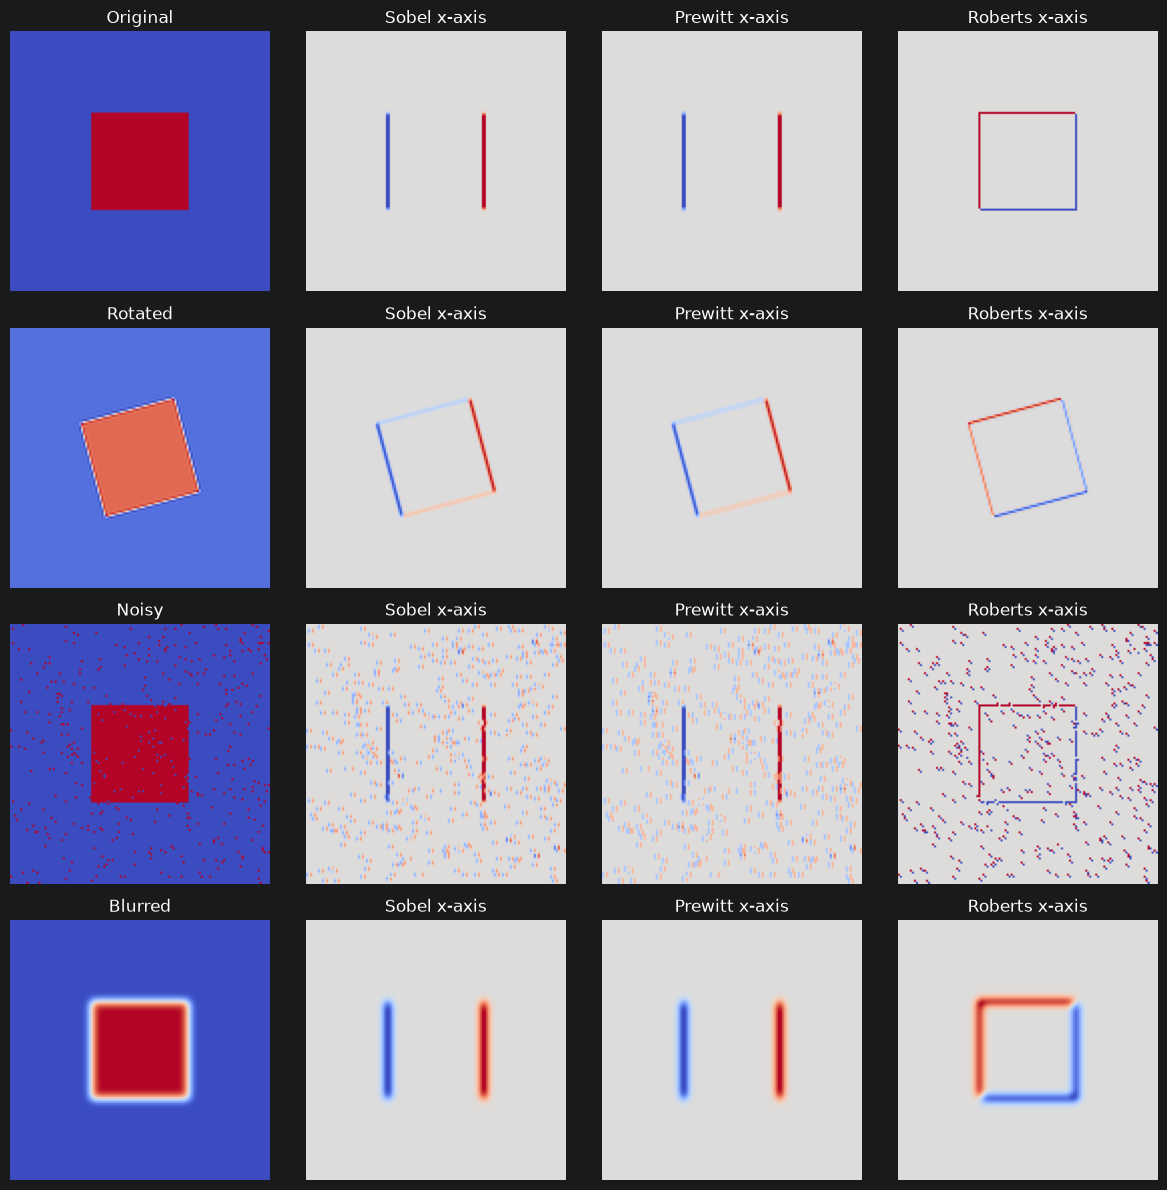

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import random_noise
from scipy.signal import convolve2d
from scipy.ndimage import rotate, gaussian_filter

# Create a blank image with a square
size = 128
img = np.zeros((size, size))
img[40:88, 40:88] = 1

# Rotate the image by 15 degrees
rotated_img = rotate(img, angle=15, reshape=False)

# Add noise (salt & pepper)
noisy_img = random_noise(img, mode='s&p', amount=0.05)
noisy_img = (noisy_img * 255).astype(np.uint8)

# Apply Gaussian filter
blurred_img = gaussian_filter(img, sigma=2)

# Define edge detection kernels (X-direction only)
sobel_x = np.array([[-1, 0, 1], 
                    [-2, 0, 2], 
                    [-1, 0, 1]])

prewitt_x = np.array([[-1, 0, 1], 
                      [-1, 0, 1], 
                      [-1, 0, 1]])

roberts_x = np.array([[1, 0], 
                      [0, -1]])

# Function to apply filters
def apply_filters(img):
    return [
        img, 
        convolve2d(img, sobel_x), 
        convolve2d(img, prewitt_x), 
        convolve2d(img, roberts_x)
    ]

# Apply filters to all images
original_results = apply_filters(img)
rotated_results = apply_filters(rotated_img)
noisy_results = apply_filters(noisy_img)
blurred_results = apply_filters(blurred_img)

# Plot results
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
titles = ['Original', 'Sobel x-axis', 'Prewitt x-axis', 'Roberts x-axis']
images = [original_results, rotated_results, noisy_results, blurred_results]
row_titles = ['Original', 'Rotated', 'Noisy', 'Blurred']

for row in range(4):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(images[row][col], cmap='coolwarm')
        if col == 0:
            ax.set_title(row_titles[row])
        else:
            ax.set_title(titles[col])
        ax.axis('off')

plt.tight_layout()
plt.show()

**Note:**  
We can also use the predefined functions in libraries such as `skimage.filters`. These implementations are optimized and provide more flexibility.


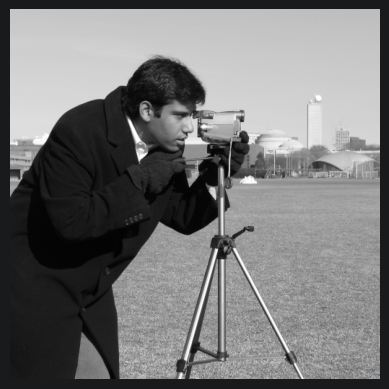

In [20]:
# Load image
img_gray = data.camera()

# Display the image
plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.show()

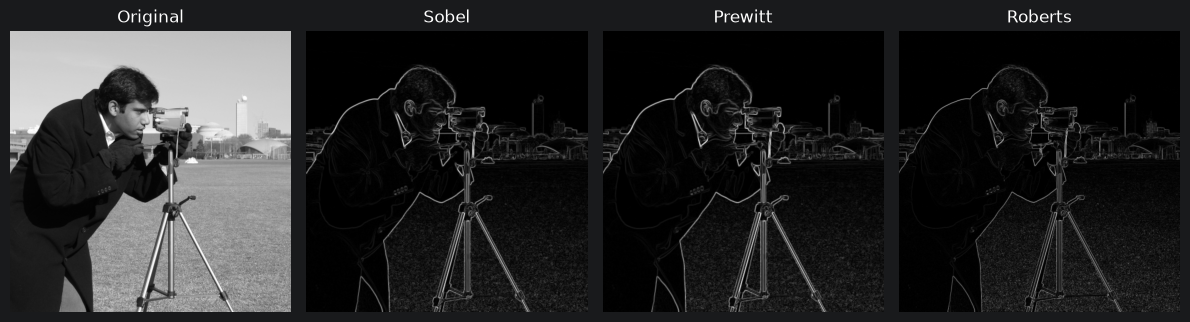

In [21]:
from skimage import filters

# Apply filters to the grayscale image
img_gray_results = [img_gray, filters.sobel(img_gray), filters.prewitt(img_gray), filters.roberts(img_gray)]

# Plot results
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
titles = ['Original', 'Sobel', 'Prewitt', 'Roberts']

for col in range(4):
    ax = axes[col]
    ax.imshow(img_gray_results[col], cmap='gray')
    ax.set_title(titles[col])
    ax.axis('off')

plt.tight_layout()
plt.show()

### Implement a simplified Canny edge detector (individual work)
Implement a **simplified version** of the Canny edge detector. This version includes Gaussian smoothing, gradient computation, and thresholding, but omits non-maximum suppression and [hysteresis thresholding](https://scikit-image.org/docs/0.24.x/auto_examples/filters/plot_hysteresis.html).

**Implement the `adjust_saturation` function:**
- input arguments:
   - `image`: numpy array
   - `sigma`: float, standard deviation of the Gaussian kernel
   - `threshold`: float, minimum edge strength for detection
- output:
   - binary image with detected edges

**Instructions:**
1. **Apply Gaussian smoothing** to reduce noise.
2. **Compute gradients** using **Sobel filters** to detect vertical and horizontal edges.
3. **Calculate edge magnitude** by combining the gradient components.
4. **Normalize** the magnitude to ensure values range between 0 and 1.
5. **Apply thresholding** to remove weak edges and keep only significant ones.

**Hints:**
- Use `scipy.signal.convolve2d` with `mode="same"` to preserve the original image size.
- Experiment with different `threshold` values to observe their effect on edge detection.

#### Code (scroll down)

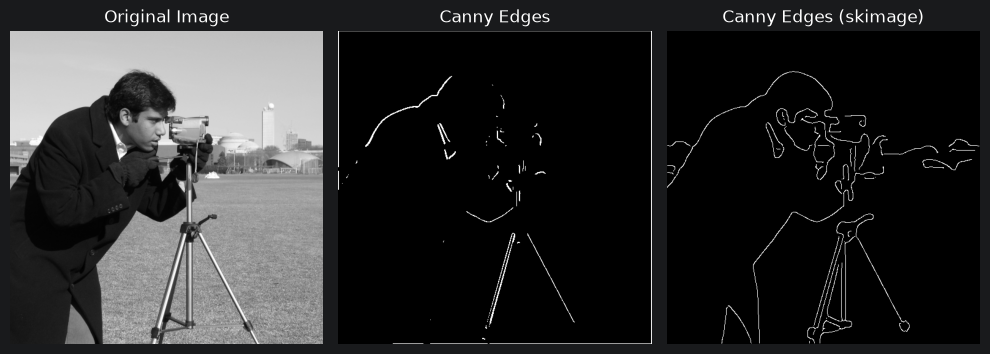

In [37]:
from skimage import feature

sobel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

def canny(image, sigma=1.4, threshold=0.3):
    image = filters.gaussian(image, sigma=sigma)
    # The complete code will be provided during the exercise

    img_sx = convolve2d(image, sobel_x, mode='same')
    img_sy = convolve2d(image, sobel_y, mode='same')

    magnitudes = np.hypot(img_sx, img_sy) # hypot suggested by AI, otherwise use list comprehension like magnitudes = [sqrt(x*x + y*y) for x in img_sx for y in img_sy]

    magnitudes_normalized = (magnitudes - np.min(magnitudes)) / (np.max(magnitudes) - np.min(magnitudes))
    edges_canny = magnitudes_normalized > threshold
    return edges_canny

# Apply Canny edge detection
edges = canny(img_gray, sigma=1.4, threshold=0.3)
edges_skimage = feature.canny(img_gray, sigma=3.5)

# Display results
fig, ax = plt.subplots(1, 3, figsize=(10, 5))

ax[0].imshow(img_gray, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis('off')

ax[1].imshow(edges, cmap='gray')
ax[1].set_title('Canny Edges')
ax[1].axis('off')

ax[2].imshow(edges_skimage, cmap='gray')
ax[2].set_title('Canny Edges (skimage)')
ax[2].axis('off')

plt.tight_layout()
plt.show()

# Next week - 1st writing test!